# Retention at two hidden layers

**Question:** With surplus capacity, does standardization preserve a learned feature while its task is absent, at either layer?

This is one absence-duration sweep, with two cases from 02b: two tasks share a first layer, or four tasks share two different first layers. Train all tasks for 1M examples, then train only task 1 for 0, 10k, 100k or 500k examples. Each absence starts from the same learned checkpoint (longer absences extend the same stream). Return the last task for 20k examples on identical test streams. Return branches never change the continuing absence trajectory.

Five paired GPU seeds per duration and case. Autostep with standardization is the baseline, using the settings from 02b; no hyperparameter search. Widths are 15 → 30 and 30 → 60, with capacity to represent every teacher simultaneously. Tasks switch every 10k examples, without task IDs. Noise standard deviation is 1.

At the learned checkpoint, match each dormant teacher feature to its most correlated learner unit, using absolute correlation on 2,048 fixed inputs. Keep those matches fixed throughout the absence; matches need not be one-to-one. Measure raw firing disagreement with the checkpoint. For layer 2, also hold its checkpoint inputs fixed to separate changes in its own computation from changes arriving through layer 1. These probes do not update the learner. The metric concerns matched features, not every hidden unit.

The notebook contains the exact experiment definitions used for the recorded run. The displayed outputs were collected by executing these definitions in a standalone GPU process. Existing notebooks were not modified.


In [ ]:
from functools import partial
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

In [ ]:
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
THRESHOLD, FIRING = 2, .3
INIT_RATE, META_RATE, EMA_RATE = 1e-5, .02, 1e-3
VAR_FLOOR = .01
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (10_000, N_INPUTS)), dtype=jnp.float32)
import time


In [ ]:
def init_task(key, first):
    """Second layer and readout of one task, on top of the given first layer."""
    second_key, out_key = jax.random.split(key)
    second = jax.random.rademacher(second_key, (WIDTH, WIDTH), dtype=jnp.float32)
    out = jax.random.rademacher(out_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    # Each second-layer threshold is the half-integer that makes the unit fire closest to 30% of the time.
    sums = second @ (first @ PROBE.T > THRESHOLD)
    candidates = jnp.arange(-WIDTH, WIDTH) + .5
    rates = (sums[:, None] > candidates[:, None]).mean(-1)
    return second, candidates[jnp.abs(rates - FIRING).argmin(1)], out


def init_teachers(key, groups):
    """Tasks 2k + 1 and 2k + 2 share first layer k + 1."""
    first_key, task_key = jax.random.split(key)
    first = jnp.repeat(jax.random.rademacher(first_key, (groups, WIDTH, N_INPUTS), dtype=jnp.float32), 2, axis=0)
    return first, *jax.vmap(init_task)(jax.random.split(task_key, 2 * groups), first)


def target(teacher, x):
    first, second, thresholds, out = teacher
    h = (first @ x > THRESHOLD).astype(jnp.float32)
    return out @ (second @ h > thresholds).astype(jnp.float32)


def true_layers(teachers, groups):
    """The teacher LTUs as hidden layers (unit, input + bias): each first layer once, then every task's second layer."""
    first, second, thresholds, _ = teachers
    layer1 = jnp.append(first[::2].reshape(-1, N_INPUTS), jnp.full((groups * WIDTH, 1), -THRESHOLD), axis=1)
    # A task's second-layer units read only the first-layer units of its own group.
    group = jax.nn.one_hot(jnp.arange(2 * groups) // 2, groups)
    layer2 = jnp.einsum('tij,tk->tikj', second, group).reshape(2 * groups * WIDTH, groups * WIDTH)
    return layer1, jnp.append(layer2, -thresholds.reshape(-1, 1), axis=1)
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple  # two hidden layers (unit, input + bias), then the readout (output, unit + bias)
    opt: object
    means: tuple  # running mean of each hidden unit
    slopes: tuple  # running mean of sigma'(z) x
    covs: tuple  # running covariance of the unit with sigma'(z) x


def init_learner(key, autostep, widths, hidden):
    if hidden is None:
        hidden, fan_in = [], N_INPUTS
        for subkey, width in zip(jax.random.split(key), widths):
            bound = jnp.where(autostep, INIT_RATE, np.sqrt(3 / fan_in))
            hidden.append(bound * jax.random.uniform(subkey, (width, fan_in + 1), minval=-1., maxval=1.).at[:, -1].set(0.))
            fan_in = width
    weights = (*hidden, jnp.zeros((N_OUTPUTS, widths[-1] + 1)))
    return Learner(weights, OPTIMIZER.init(weights),
                   tuple(jnp.full(len(w), .5) for w in hidden),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in hidden),
                   tuple(jnp.zeros_like(w) for w in hidden))


def forward(weights, x, learner, standardize, frozen):
    sources, means, slopes, covs = [], [], [], []
    for layer, (w, mean, slope, cov) in enumerate(zip(weights[:-1], learner.means, learner.slopes, learner.covs)):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        bits = ltu(z)
        # Centering, with the backward pass accounting for how the mean changes with the input weights.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(bits) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid * (1 - sigmoid))[:, None] * source)
        slope = slope + EMA_RATE * (derivative - slope)
        correction = jnp.sum(slope * w, axis=1)
        centered = jax.lax.stop_gradient(bits - mean)
        h = bits - mean + (jax.lax.stop_gradient(correction) - correction)
        # Standardization: also divide by the running standard deviation, accounting for how it changes.
        cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * w, axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        x = jnp.where(standardize, h / jnp.sqrt(floored), bits)
        if frozen and layer == 0:
            x = bits  # the baseline's frozen second layer reads the first-layer bits, like the teacher
        means.append(mean)
        slopes.append(slope)
        covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def update(learner, x, y, autostep, rate, standardize, frozen):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, standardize, frozen)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, *stats)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    adaptive, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    updates = jax.tree.map(lambda a, g: jnp.where(autostep, a, -rate * g), adaptive, grads)
    if frozen:
        updates = (*map(jnp.zeros_like, updates[:-1]), updates[-1])
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, *stats), 2 * loss_value / N_OUTPUTS

In [ ]:
@partial(jax.jit, static_argnames=('groups','nseeds','given'))
def setup(groups, nseeds=5, given=False):
 def one(seed):
  kt,kl,kr=jax.random.split(jax.random.PRNGKey(seed),3)
  teachers=init_teachers(kt,groups)
  widths=(15*groups,30*groups)
  learner=init_learner(kl,True,widths,None)
  if given:
   h1,h2=true_layers(teachers,groups)
   w1,w2,wo=learner.weights
   w1=w1.at[:len(h1)].set(h1)
   # Raw teacher bits = .5 * standardized bits + .5 at initialization.
   w2=w2.at[:len(h2)].set(0.)
   w2=w2.at[:len(h2),:len(h1)].set(.5*h2[:,:-1])
   w2=w2.at[:len(h2),-1].set(h2[:,-1]+.5*h2[:,:-1].sum(1))
   learner=learner._replace(weights=(w1,w2,wo),opt=OPTIMIZER.init((w1,w2,wo)))
  return learner,teachers,kr
 return jax.vmap(one)(jnp.arange(nseeds))

@partial(jax.jit, static_argnames=('steps','groups','active','method','freeze'))
def segment(learner,teachers,rng,steps,groups,active,method='autostep',freeze=False):
 def one(learner,teachers,rng):
  def sample(carry,i):
   learner,rng=carry
   rng,kx,kn=jax.random.split(rng,3)
   x=jax.random.rademacher(kx,(N_INPUTS,),dtype=jnp.float32)
   task=(i//10000)%(2*groups) if active=='all' else jnp.asarray(int(active))
   teacher=jax.tree.map(lambda w:w[task],teachers)
   y=target(teacher,x)+jax.random.normal(kn,(N_OUTPUTS,))
   new,mse=update(learner,x,y,method=='autostep',2.**-9,True,False)
   if freeze:
    new=new._replace(weights=(*learner.weights[:-1],new.weights[-1]))
   return (new,rng),mse
  def window(carry,block):
   carry,mse=jax.lax.scan(sample,carry,block*1000+jnp.arange(1000))
   return carry,mse.mean()
  (learner,rng),mse=jax.lax.scan(window,(learner,rng),jnp.arange(steps//1000))
  return learner,rng,mse
 return jax.vmap(one)(learner,teachers,rng)

@jax.jit
def probe(learner):
 def one(l):
  hs=[];sources=[];x=PROBE[:2048]
  for w,m in zip(l.weights[:-1],l.means):
   sources.append(x)
   h=(x@w[:,:-1].T+w[:,-1]>0).astype(jnp.float32)
   hs.append(h)
   x=(h-m)/jnp.sqrt(jnp.maximum(m*(1-m),VAR_FLOOR))
  return tuple(hs),tuple(sources)
 return jax.vmap(one)(learner)

def ready(x):
 jax.block_until_ready(x);return x



In [ ]:
def correlation(a,b):
 a=a-a.mean(axis=1,keepdims=True);b=b-b.mean(axis=1,keepdims=True)
 return jnp.einsum('spi,spj->sij',a,b)/jnp.maximum(jnp.sqrt(jnp.sum(a*a,axis=1)[:,:,None]*jnp.sum(b*b,axis=1)[:,None,:]),1e-8)

@jax.jit
def teacher_bits(t):
 def one(t):
  f,s,thresholds,_=jax.tree.map(lambda a:a[-1],t)
  h=(PROBE[:2048]@f.T>THRESHOLD).astype(jnp.float32)
  return h,(h@s.T>thresholds).astype(jnp.float32)
 return jax.vmap(one)(t)

@jax.jit
def assess(l,ref_h,ref_src,truth,indices):
 hs,_=probe(l)
 local2=jax.vmap(lambda w,x:(x@w[:,:-1].T+w[:,-1]>0).astype(jnp.float32))(l.weights[1],ref_src[1])
 scores=[]
 for i,h in enumerate(hs):
  idx=indices[i]
  selected=jnp.take_along_axis(h,idx[:,None,:],axis=2)
  old=jnp.take_along_axis(ref_h[i],idx[:,None,:],axis=2)
  corr=correlation(h,truth[i])
  quality=jnp.take_along_axis(corr,idx[:,:,None],axis=1) # diagonal below separately
  quality=jax.vmap(lambda c,j:jnp.abs(c[j,jnp.arange(j.shape[0])]).mean())(corr,idx)
  flip=(selected!=old).mean(axis=(1,2))
  if i==1:
   local=jnp.take_along_axis(local2,idx[:,None,:],axis=2)
   local_flip=(local!=old).mean(axis=(1,2))
  else: local_flip=flip
  scores.append(jnp.stack((quality,flip,local_flip),axis=-1))
 return jnp.stack(scores,axis=1)



In [ ]:
started=time.perf_counter();results={}
for groups in (1,2):
 begin=time.perf_counter()
 l,t,r=ready(setup(groups))
 l,r,warm=ready(segment(l,t,r,1000000,groups,'all'))
 ref_h,ref_src=ready(probe(l));truth=ready(teacher_bits(t))
 indices=tuple(jnp.argmax(jnp.abs(correlation(h,b)),axis=1) for h,b in zip(ref_h,truth))
 checkpoints=[];metrics=[];curves=[];previous=0
 for gap in (0,10000,100000,500000):
  if gap:
   l,r,m=ready(segment(l,t,r,gap-previous,groups,'0'))
   curves.append(np.asarray(m))
  metrics.append(np.asarray(ready(assess(l,ref_h,ref_src,truth,indices))))
  # Identical return RNG for every absence; evaluate adaptation to the dormant task.
  _,_,returned=ready(segment(l,t,jax.random.split(jax.random.PRNGKey(700),5),20000,groups,str(2*groups-1)))
  checkpoints.append(np.asarray(returned))
  previous=gap
 results[groups]={'warm':np.asarray(warm),'absence':np.concatenate(curves,axis=1),'metrics':np.array(metrics),'return':np.array(checkpoints),'seconds':time.perf_counter()-begin}
 print('GROUPS',groups,'SECONDS',results[groups]['seconds'],flush=True)
 print('warm final20k RMSE',np.sqrt(np.asarray(warm)[:,-20:].mean(1)),flush=True)
 print('metrics [gap,layer; quality, global flips, local flips]',np.array(metrics).mean(1),flush=True)
 print('return first10k RMSE',np.sqrt(np.array(checkpoints)[:,:,:10].mean(2)).mean(1),flush=True)
print('TOTAL',time.perf_counter()-started,flush=True)


Case: 2 tasks; 56.3s including compilation
Mean matched-feature metrics [gap, layer, (teacher correlation, raw-input flips, fixed-input flips)]:
[[[0.99809295 0.         0.        ]
  [0.99168855 0.         0.        ]]

 [[0.9978501  0.00166016 0.00166016]
  [0.8804898  0.0627832  0.05708984]]

 [[0.998882   0.00134766 0.00134766]
  [0.86800414 0.06819336 0.06622071]]

 [[0.9985868  0.00148438 0.00148438]
  [0.85881776 0.07204102 0.0681543 ]]]
Return first 10k RMSE by absence: [1.0315382 1.0824302 1.1219876 1.2530458]
Case: 4 tasks; 61.8s including compilation
Mean matched-feature metrics [gap, layer, (teacher correlation, raw-input flips, fixed-input flips)]:
[[[0.99452275 0.         0.        ]
  [0.9101896  0.         0.        ]]

 [[0.9776583  0.00918945 0.00918945]
  [0.753775   0.09163086 0.07947265]]

 [[0.9655838  0.01480469 0.01480469]
  [0.73790014 0.09821289 0.08049805]]

 [[0.9350031  0.02864258 0.02864258]
  [0.6826792  0.12898436 0.09600586]]]
Return first 10k RMSE by a

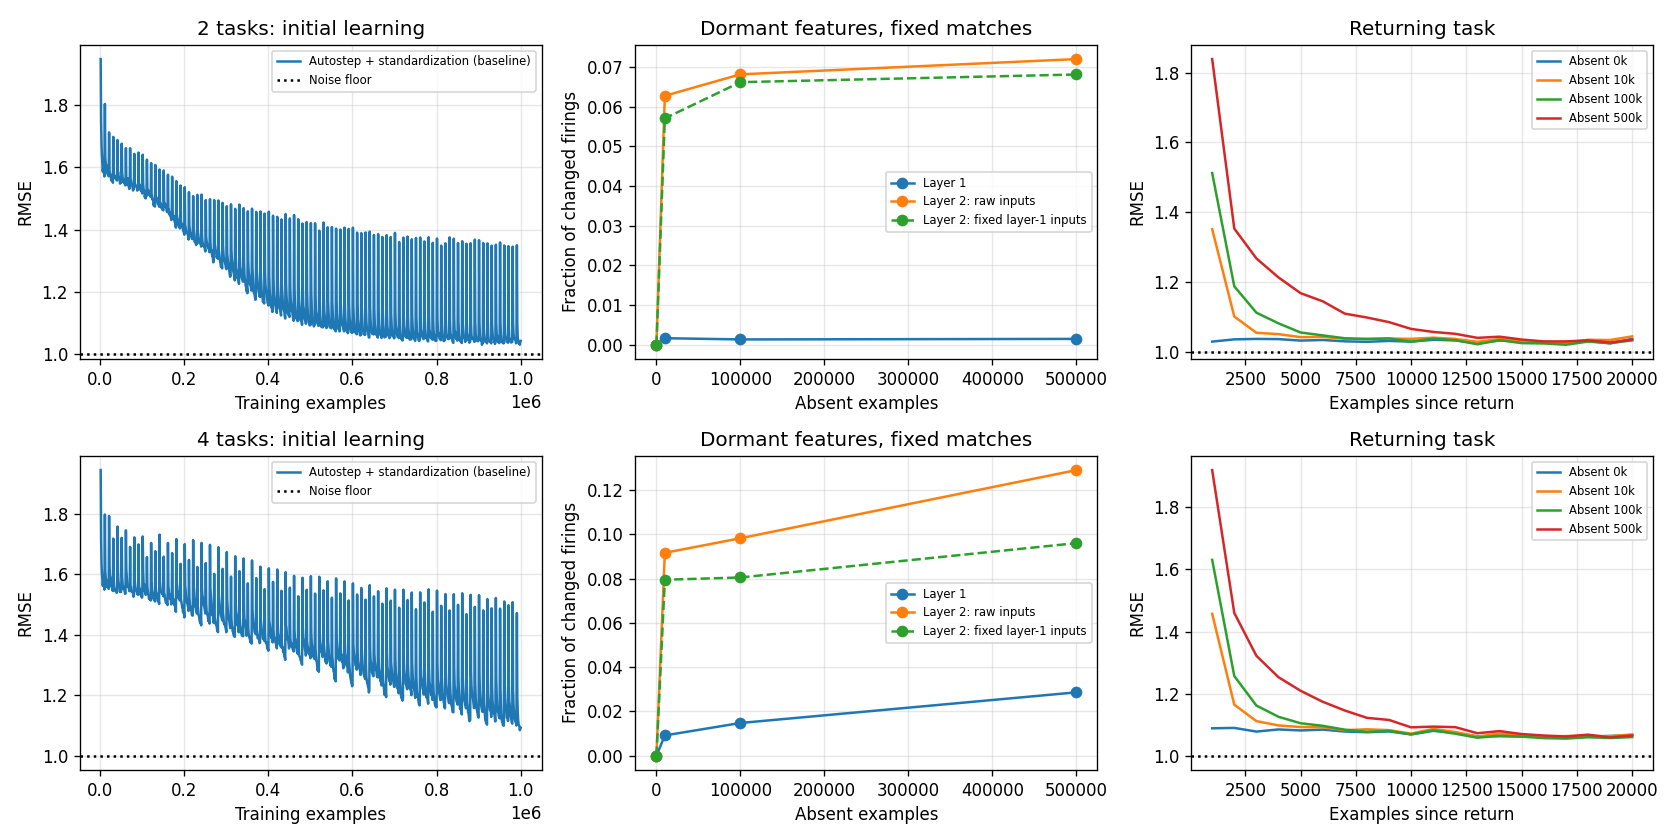

In [ ]:
gaps = np.array([0, 10_000, 100_000, 500_000])
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, (groups, result) in enumerate(results.items()):
    ax = axes[row, 0]
    ax.plot(np.arange(1, 1001)*1000, np.sqrt(result['warm']).mean(0), label='Autostep + standardization (baseline)')
    ax.axhline(1., color='black', ls=':', label='Noise floor')
    ax.set(xlabel='Training examples', ylabel='RMSE', title=f'{2*groups} tasks: initial learning')
    ax = axes[row, 1]
    metrics = result['metrics'].mean(1)
    ax.plot(gaps, metrics[:, 0, 1], 'o-', label='Layer 1')
    ax.plot(gaps, metrics[:, 1, 1], 'o-', label='Layer 2: raw inputs')
    ax.plot(gaps, metrics[:, 1, 2], 'o--', label='Layer 2: fixed layer-1 inputs')
    ax.set(xlabel='Absent examples', ylabel='Fraction of changed firings', title='Dormant features, fixed matches')
    ax = axes[row, 2]
    for gap, curve in zip(gaps, result['return']):
        ax.plot(np.arange(1,21)*1000, np.sqrt(curve).mean(0), label=f'Absent {gap//1000}k')
    ax.axhline(1., color='black', ls=':')
    ax.set(xlabel='Examples since return', ylabel='RMSE', title='Returning task')
for ax in axes.flat:
    ax.grid(True, alpha=.3)
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


## What this experiment establishes

Read the feature measurements before the return curves: return RMSE also includes relearning a shared readout. A longer return transient alone does not establish that hidden features were lost. At zero absence the last task is still active, so that curve is a continuity reference, not a matched switch control.

The first-layer and second-layer probes separate preservation of a local computation from preservation of the entire input-to-feature hierarchy. Upper-layer disagreement with fixed inputs is direct evidence that its local computation changed. Matching features only after the absence would hide that change.

This is an empirical retention test of the existing method, not a demonstration of indefinite stability or a validated algorithmic fix. It does not test new-task reuse, task-count scaling independently of architecture, or the effect of prior recurrence frequency. The two cases differ in both sharing and task count, so their difference cannot be attributed solely to depth.


## Frozen-weight control

Repeat the shared-first-layer case from the identical learned checkpoint, but freeze both hidden weight matrices during the 500k absence and 20k return. Normalization statistics and the readout still learn. Five paired seeds; this is the frozen-weight arm of the absence experiment. The firing metric below averages all units, unlike the matched dormant-unit metric above. This is a privileged diagnostic, not a proposed learner.

In [ ]:
start=time.perf_counter()
l,t,r=ready(setup(1))
l,r,_=ready(segment(l,t,r,1000000,1,'all'))
h0,_=ready(probe(l))
l,r,_=ready(segment(l,t,r,500000,1,'0',freeze=True))
h1,_=ready(probe(l))
_,_,m=ready(segment(l,t,jax.random.split(jax.random.PRNGKey(700),5),20000,1,'1',freeze=True))
result={'seconds':time.perf_counter()-start,'flip':[np.asarray((a!=b).mean((1,2))) for a,b in zip(h0,h1)],'return':np.asarray(m)}
print('Frozen hidden weights, moving normalization:',result,flush=True)


Elapsed: 48.1s
All-unit firing disagreement by layer: [0.0, 0.009078776463866234]
Return first-10k RMSE: 1.22137
